# Degradación de la red viaria de Granada bajo lluvia (cuaderno mínimo)

Cuaderno de extremo a extremo con **un escenario** (*moderada*). Carga la red, importa la muestra de trayectos, la verifica y calcula el **factor de degradación** por trayecto (tiempo con lluvia / tiempo en seco). Toda la lógica vive en el módulo `trafico_lluvia`; aquí solo se narra y se muestra.

Ejecutar: `uv run jupyter nbconvert --to notebook --execute --inplace cuaderno_lluvia.ipynb`

In [1]:
from pathlib import Path

from trafico_lluvia import (
    ESCENARIOS, analizar, cargar_muestra, cargar_red,
    guardar_tablas, tabla_escenarios, verificar_muestra,
)

SALIDAS = Path("salidas")  # carpeta de salida única

## 1. La red

In [2]:
G = cargar_red()
km = sum(d.get("length", 0) for _, _, d in G.edges(data=True)) / 1000
print(f"Red de Granada: {len(G.nodes):,} nodos, {len(G.edges):,} aristas, {km:,.0f} km")

Red de Granada: 5,221 nodos, 10,243 aristas, 818 km


## 2. La muestra de trayectos

> **Es una muestra, no un modelo de la ciudad.** Son 16 pares periferia → centro (9 corredores más el par extra de Parking del Triunfo, destino Puerta Real, nodo `534921646`), elegidos para tener accesos representativos. Los resultados describen estos trayectos, no el tráfico de Granada en conjunto.

In [3]:
muestra = cargar_muestra(G)
verificar_muestra(G, muestra)  # falla con mensaje claro si falta ruta o los tiempos secos no coinciden con trayectos.csv (< 1 s)
print(f"Muestra verificada: {len(muestra)} pares, {muestra.corredor.nunique()} corredores; tiempos secos coinciden con trayectos.csv.")
muestra

Muestra verificada: 16 pares, 10 corredores; tiempos secos coinciden con trayectos.csv.


,corredor,origen,destino,tiempo_seco_csv_s
0,Camino de Ronda,4520478554,534921646,359.0
1,Camino de Ronda,4520478553,534921646,357.0
2,Av. de Andalucía,559691143,534921646,680.0
3,Av. de Andalucía,3435223168,534921646,677.0
4,Ctra. de Málaga,983525310,534921646,646.0
5,Ctra. de Málaga,7260359798,534921646,693.0
6,Ctra. de Murcia,1457605871,534921646,778.0
7,Ctra. de Murcia,1457605799,534921646,711.0
8,Ronda Sur,83301193,534921646,493.0
9,Ronda Sur,8090482736,534921646,484.0


## 3. Escenario *moderada*

Reducción de velocidad por clase de vía (fuente: ticket 02; para Granada es extrapolación).

In [4]:
escenario = ESCENARIOS["moderada"]
tabla_escenarios([escenario])

,escenario,intensidad_mm_h,reduccion_urbana,rango_urbana,reduccion_interurbana,rango_interurbana,confianza,hora_punta,fuente
0,moderada,"2,5 - 6,35",0.07,5% a 10%,0.06,4% a 10%,Alta: HCM y varios estudios convergen.,laborable sintética (solo etiqueta; no cambia ...,ticket 02


## 4. Degradación por trayecto

La ruta se **recalcula** con los tiempos degradados (cada arista se reescala por 1/(1−δ) según su clase de vía), no se reescala la ruta seca.

In [5]:
resultado = analizar(G, muestra, [escenario])
tabla = resultado.por_trayecto[
    ["corredor", "tiempo_seco_s", "tiempo_lluvia_s", "factor_degradacion", "ruta_cambia"]
].round({"tiempo_seco_s": 0, "tiempo_lluvia_s": 0, "factor_degradacion": 3})
tabla

,corredor,tiempo_seco_s,tiempo_lluvia_s,factor_degradacion,ruta_cambia
0,Camino de Ronda,359.0,386.0,1.075,False
1,Camino de Ronda,357.0,384.0,1.075,False
2,Av. de Andalucía,680.0,727.0,1.068,False
3,Av. de Andalucía,677.0,723.0,1.068,False
4,Ctra. de Málaga,646.0,690.0,1.068,False
5,Ctra. de Málaga,693.0,740.0,1.069,False
6,Ctra. de Murcia,778.0,837.0,1.075,False
7,Ctra. de Murcia,711.0,764.0,1.075,False
8,Ronda Sur,493.0,528.0,1.073,False
9,Ronda Sur,484.0,520.0,1.073,False


In [6]:
print(f"Factor de degradación: mín {tabla.factor_degradacion.min():.3f}, máx {tabla.factor_degradacion.max():.3f}; "
      f"trayectos que cambian de ruta: {int(tabla.ruta_cambia.sum())} de {len(tabla)}")
resultado.por_corredor

Factor de degradación: mín 1.068, máx 1.075; trayectos que cambian de ruta: 0 de 16


,escenario,corredor,factor_medio,factor_min,factor_max,trayectos
0,moderada,Camino de Ronda,1.075269,1.075269,1.075269,2
1,moderada,Av. de Andalucía,1.067974,1.067963,1.067985,2
2,moderada,Ctra. de Málaga,1.068421,1.068182,1.068660,2
3,moderada,Ctra. de Murcia,1.075269,1.075269,1.075269,2
4,moderada,Ronda Sur,1.072960,1.072883,1.073036,2
5,moderada,Ctra. de la Sierra,1.075269,1.075269,1.075269,1
6,moderada,Av. de Dílar,1.075269,1.075269,1.075269,2
7,moderada,Av. de Pulianas,1.075269,1.075269,1.075269,1
8,moderada,Camino de Alfacar,1.075269,1.075269,1.075269,1
9,moderada,Parking del Triunfo (Av. Constitución),1.075269,1.075269,1.075269,1


## 5. Límites (resumen)

Con un único factor de velocidad el modelo da un factor ≈ 1/(1−δ): **no reproduce el colapso** observado cerca de capacidad. Sin capacidad, semáforos, incidentes ni cambios de demanda. Los límites completos están en la sección «Límites del modelo», al final.

In [7]:
guardar_tablas(resultado, SALIDAS)
sorted(p.name for p in SALIDAS.iterdir())

['degradacion_por_corredor.csv', 'degradacion_por_trayecto.csv']

# Escenarios completos, sensibilidad y degradación por corredor

Los cuatro escenarios (ligera, moderada, fuerte, torrencial) con valor central y rango. La columna `confianza` copia las etiquetas del ticket 02. **El escenario *torrencial* es una extrapolación** (confianza baja): no hay datos de Granada y los de la bibliografía apenas cubren esas intensidades.

**Decisión urbana/interurbana.** Las vías `motorway`/`trunk` (y sus enlaces) usan la reducción interurbana; el resto, la urbana. Es una **decisión propuesta por la spec** (no está en ningún ticket), **aún por confirmar en revisión**: es lo que hace que el factor varíe entre trayectos (con un factor único la criticidad degeneraría en betweenness puro). **Criterio `any()`:** cuando OSM da a una arista una lista de tipos de vía (p. ej. `["primary", "motorway_link"]`), se trata como interurbana si *alguno* de ellos es `motorway`/`motorway_link`/`trunk`/`trunk_link`.

**Hora punta laborable sintética:** es solo etiqueta y contexto (columna `hora_punta`); no cambia el cálculo.

In [8]:
from trafico_lluvia.sensibilidad import (
    analizar_con_rango, cambios_de_ruta, curva_sensibilidad, figura_curva, figura_principal,
)

tabla_esc = tabla_escenarios(ESCENARIOS)
tabla_esc.to_csv(SALIDAS / "escenarios.csv", index=False)
tabla_esc

,escenario,intensidad_mm_h,reduccion_urbana,rango_urbana,reduccion_interurbana,rango_interurbana,confianza,hora_punta,fuente
0,ligera,"< 2,5",0.03,1% a 5%,0.03,2% a 5%,"Media: el HCM 6 dice 0; los empíricos, −2 a −5 %.",laborable sintética (solo etiqueta; no cambia ...,ticket 02
1,moderada,"2,5 - 6,35",0.07,5% a 10%,0.06,4% a 10%,Alta: HCM y varios estudios convergen.,laborable sintética (solo etiqueta; no cambia ...,ticket 02
2,fuerte,"6,35 - 30",0.11,7% a 20%,0.09,6% a 17%,"Alta en capacidad (HCM), media en velocidad (r...",laborable sintética (solo etiqueta; no cambia ...,ticket 02
3,torrencial,> 30,0.22,15% a 35%,0.20,15% a 35%,Baja: extrapolación de eventos extremos; no es...,laborable sintética (solo etiqueta; no cambia ...,ticket 02


### Contexto: Δ de capacidad del ticket 02 (NO se aplican)

El modelo aplica **solo** la reducción de velocidad. Los Δ de capacidad de la investigación se muestran únicamente como contexto de lo que no se modela.

In [9]:
from trafico_lluvia import tabla_capacidad_contexto

tabla_capacidad_contexto()

,escenario,delta_capacidad,aplicado,fuente
0,ligera,−3 % (−2 a −8),no,ticket 02
1,moderada,−7 % (−6 a −10),no,ticket 02
2,fuerte,−14 % (−11 a −30),no,ticket 02
3,torrencial,−25 % (−20 a −40) + cierres,no,ticket 02


### Definición del agregado por corredor

- **Por trayecto:** factor = tiempo con lluvia (ruta recalculada) / tiempo seco, con la reducción central; `factor_minimo` y `factor_maximo` usan los extremos del rango.
- **Por corredor:** `factor_medio` es la **media aritmética** del factor central de sus trayectos; la banda (`banda_min`, `banda_max`) es la media de los factores con la reducción mínima y máxima del rango. Se añade `factor_peor_trayecto` (máximo).

In [10]:
res = analizar_con_rango(G, muestra, list(ESCENARIOS.values()))
res.por_trayecto.to_csv(SALIDAS / "escenarios_por_trayecto.csv", index=False)
res.por_corredor.to_csv(SALIDAS / "escenarios_por_corredor.csv", index=False)
res.por_corredor.pivot(index="corredor", columns="escenario", values="factor_medio")[list(ESCENARIOS)].round(3)

escenario,ligera,moderada,fuerte,torrencial
corredor,,,,
Av. de Andalucía,1.031,1.068,1.108,1.262
Av. de Dílar,1.031,1.075,1.124,1.282
Av. de Pulianas,1.031,1.075,1.124,1.282
Camino de Alfacar,1.031,1.075,1.124,1.282
Camino de Ronda,1.031,1.075,1.124,1.282
Ctra. de Murcia,1.031,1.075,1.124,1.282
Ctra. de Málaga,1.031,1.068,1.109,1.263
Ctra. de la Sierra,1.031,1.075,1.124,1.282
Parking del Triunfo (Av. Constitución),1.031,1.075,1.124,1.282


### Trayectos que cambian de ruta

In [11]:
cambios = cambios_de_ruta(res)
cambios.to_csv(SALIDAS / "escenarios_cambios_de_ruta.csv", index=False)
cambios

,escenario,trayectos_que_cambian,trayectos
0,ligera,0,16
1,moderada,0,16
2,fuerte,0,16
3,torrencial,0,16


### Figura principal: factor de degradación por corredor y escenario, con banda de rango

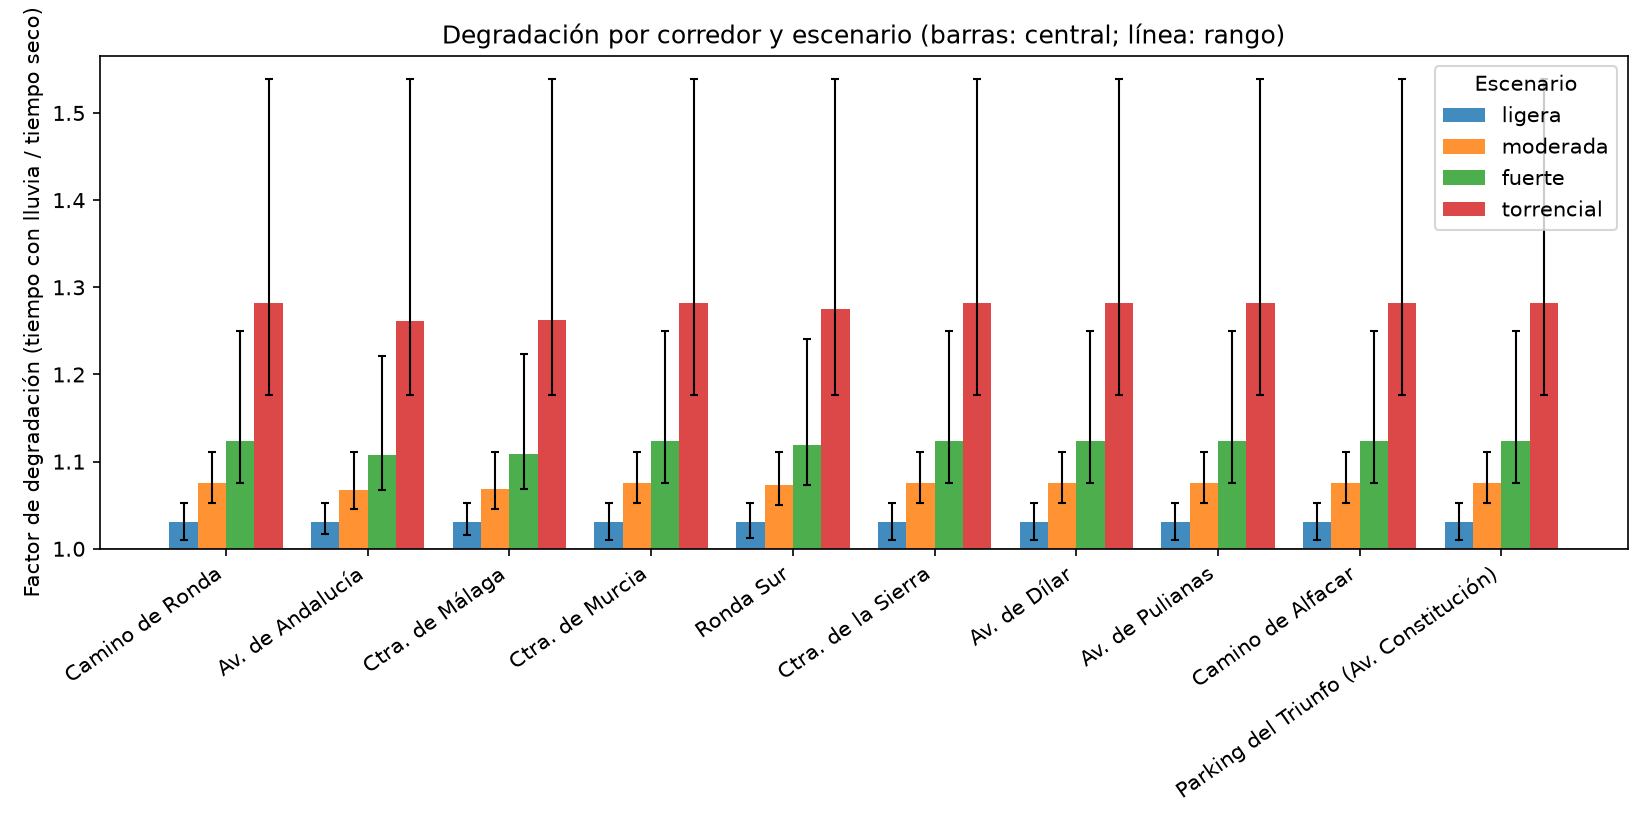

In [12]:
from IPython.display import Image
Image(filename=figura_principal(res.por_corredor, SALIDAS / "degradacion_por_corredor_escenario.png"))

### Curva de sensibilidad

Con una reducción uniforme δ el factor es ≈ 1/(1−δ); la curva muestra cuánto depende el resultado del parámetro menos seguro.

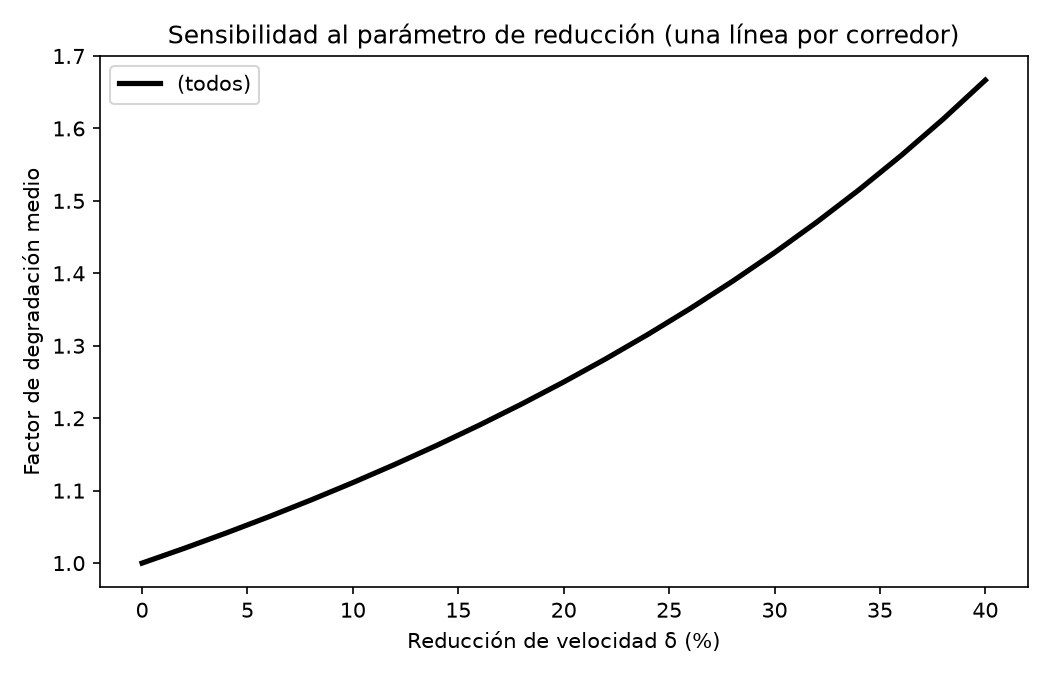

In [13]:
curva = curva_sensibilidad(G, muestra, [i / 100 for i in range(0, 41, 2)])
curva.to_csv(SALIDAS / "curva_sensibilidad.csv", index=False)
Image(filename=figura_curva(curva, SALIDAS / "curva_sensibilidad.png"))

## Visor interactivo de trayectos

Se regenera aquí mismo desde la red y la muestra verificadas, de modo que figura y datos no divergen. Es un único HTML autónomo (datos incrustados): se abre con doble clic, sin servidor. Vista canvas con leyenda por corredor; rueda para el zoom, arrastrar para mover y clic en un trayecto (lista o ruta) para acercarse a él. El botón «＋ Ruta» propone rutas nuevas (vista previa, nombre, vías con Mayús+clic, factor sobre la óptima) y «Exportar rutas» descarga un CSV que `ampliar_muestra(G, muestra, csv)` incorpora a la muestra.

**Vías forzadas:** la exportación guarda solo pares origen-destino con su tiempo óptimo; las vías intermedias forzadas para la vista previa se **descartan**.

In [14]:
from IPython.display import HTML

from trafico_lluvia import generar_visor

visor = generar_visor(G, muestra, SALIDAS / "visor_trayectos.html")
HTML(f'Visor regenerado: <a href="{visor.as_posix()}" target="_blank">{visor.as_posix()}</a> ({len(muestra)} trayectos)')

# Criticidad estructural y ranking de enlaces

`criticidad = betweenness_norm × factor_norm`, ambos en [0, 1] (ticket 04).

- **Betweenness:** de arista, ponderada por `travel_time` en seco, sobre la **red completa** (estructura), no sobre la red de la muestra. Se normaliza dividiendo por su máximo.
- **Factor degradado por enlace:** media del factor de degradación de los trayectos de la muestra cuya ruta con lluvia atraviesa el enlace, dividido por el máximo entre enlaces. Los enlaces que ningún trayecto usa quedan **fuera** del ranking.
- **Elección declarada:** «red completa + factor medio por enlace» frente a «red de la muestra» (el ticket 04 decía lo segundo; el mapa fija lo primero, y aquí se sigue el criterio de la spec).
- **Muestreo:** la betweenness exacta sobre 5.221 nodos tarda unos 5 minutos; se usa muestreo de **`k = 1000` nodos origen con semilla fija 42** (≈ 1 min). Es una aproximación: los valores absolutos tienen ruido, y por eso se comprueba la estabilidad del ranking.
- **Escenario del ranking: solo *fuerte*, por elección** (no se calcula el ranking para los demás escenarios); se usa su valor central y la estabilidad compara con los extremos de su rango. Un único factor de velocidad: la criticidad refleja estructura más desvíos, no capacidad.

In [15]:
import time
from trafico_lluvia.criticidad import (
    betweenness_aristas, calcular_criticidad, estabilidad_ranking, figura_mapa, ranking,
)

K, SEMILLA, N, ESC = 1000, 42, 15, ESCENARIOS["fuerte"]
t0 = time.time()
b = betweenness_aristas(G, k=K, semilla=SEMILLA)
crit = calcular_criticidad(G, muestra, ESC, "central", betweenness=b)
print(f"Betweenness con muestreo k={K}, semilla={SEMILLA}: {time.time() - t0:.0f} s; "
      f"enlaces usados por la muestra: {len(crit)} de {G.number_of_edges():,}")

Betweenness con muestreo k=1000, semilla=42: 61 s; enlaces usados por la muestra: 403 de 10,243


### Ranking de los enlaces más críticos (escenario *fuerte*)

In [16]:
rank = ranking(crit, N)
rank.to_csv(SALIDAS / "criticidad_ranking.csv", index=False)
crit.to_csv(SALIDAS / "criticidad_enlaces.csv", index=False)
rank.drop(columns=["u", "v", "clave"]).round(3)

,via,corredor,criticidad,betweenness_norm,factor_medio
0,Glorieta de la Aviación Española,Av. de Dílar,1.000,1.000,1.124
1,Camino de Ronda,Av. de Dílar,0.940,0.940,1.124
2,(sin nombre),Av. de Dílar,0.928,0.928,1.124
3,(sin nombre),Av. de Dílar,0.920,0.920,1.124
4,Camino de Ronda,Av. de Dílar,0.909,0.909,1.124
5,Camino de Ronda,Av. de Dílar,0.903,0.903,1.124
6,Glorieta de la Aviación Española,Av. de Dílar,0.901,0.901,1.124
7,Camino de Ronda,Av. de Dílar,0.900,0.900,1.124
8,Camino de Ronda,Av. de Dílar,0.899,0.899,1.124
9,Camino de Ronda,Av. de Dílar,0.897,0.897,1.124


### Mapa por criticidad

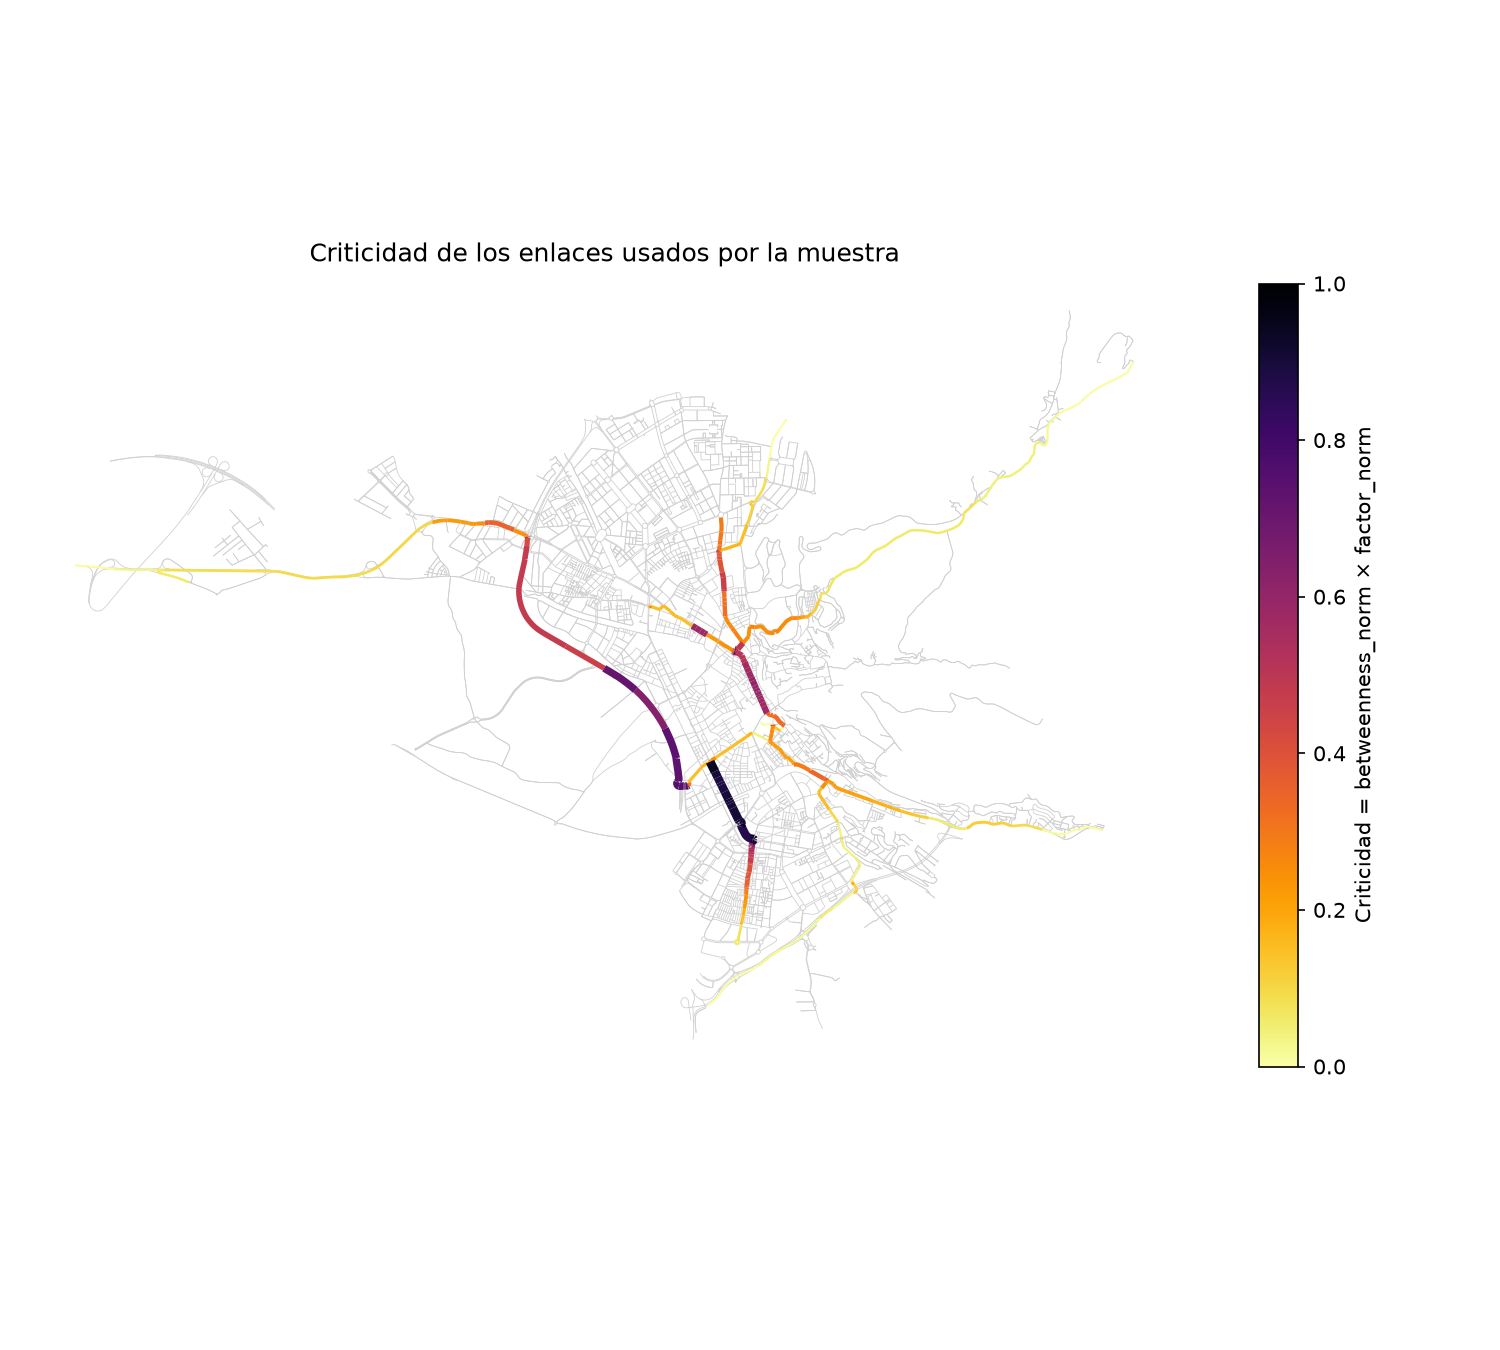

In [17]:
Image(filename=figura_mapa(G, crit, SALIDAS / "criticidad_mapa.png"))

### Estabilidad ante el rango del escenario

Se recalcula el ranking con la reducción mínima y máxima del rango (misma betweenness) y se compara con el central: solape del top-N y correlación de Spearman.

In [18]:
est = estabilidad_ranking(G, muestra, ESC, n=N, k=K, semilla=SEMILLA)
est.to_csv(SALIDAS / "criticidad_estabilidad.csv", index=False)
est.round(3)

,nivel,escenario,n,solape_top_n,spearman
0,minimo,fuerte,15,1.0,1.0
1,maximo,fuerte,15,1.0,1.0


# Límites del modelo

Lo que sigue hay que decirlo en voz alta antes de interpretar ningún número.

- **Solo un factor de velocidad.** Cada vía pierde una fracción δ de su velocidad según el escenario. No hay capacidad, ni intersecciones, ni semáforos.
- **Demanda constante.** No cambia con la lluvia. En la realidad la lluvia reduce la demanda un 15–30 %, lo que puede compensar parte de la pérdida de capacidad; aquí solo se menciona.
- **Hora punta sintética.** No hay matriz origen-destino real: la muestra son 16 pares periferia → centro, no la ciudad.
- **Sin incidentes ni comportamiento.** No hay accidentes, inundaciones, cortes, demanda inducida ni cambios de conducta.
- **Factores extrapolados.** No hay estudios revisados por pares con velocidad o capacidad bajo lluvia para Granada ni para una ciudad mediterránea española (ticket 02); cualquier factor para Granada es extrapolación y el modelo no está calibrado.

## Por qué el factor sale ≈ 1/(1−δ) y no reproduce el colapso

Si una vía reduce su velocidad una fracción δ, su tiempo de viaje se multiplica por 1/(1−δ). Con una reducción uniforme, todos los tiempos se reescalan igual y el factor de degradación de cualquier trayecto es ≈ 1/(1−δ): entre ×1,03 y ×1,28 en los escenarios del cuaderno. Es coherente con los **+2 a +6 %** de tiempo de viaje medidos en Londres con lluvia moderada-fuerte (Tsapakis et al. 2013), pero **no reproduce el colapso observado** en Granada cuando llueve.

La hipótesis mecanicista es que el colapso viene de la **amplificación cerca de capacidad**: con la demanda al 90–95 % de la capacidad, una pérdida moderada de capacidad (−5 a −15 % con lluvia ordinaria, hasta −25/−30 % con lluvia fuerte) dispara las colas y los tiempos de forma no lineal. Un modelo de un solo factor de velocidad, sin capacidad, no puede mostrarlo. Lo que sí hace es acotar el efecto físico «directo» y localizar dónde se concentra, no explicar el colapso.


# Qué haría falta para el contraste causal

El efecto físico es moderado y el colapso observado es desproporcionado. Para contrastar la hipótesis hay que comparar **velocidades observadas** en días con y sin lluvia, y ninguna fuente abierta lo permite hoy en Granada (verificado el 25/11/2026, ticket 01). Opciones y costes:

| Fuente | Qué aportaría | Coste y acceso |
|---|---|---|
| **TomTom Traffic Stats / HERE Traffic Analytics** | Velocidad histórica por segmento y fecha concreta: lo único que permite aislar un día lluvioso | Comercial, por contrato (TomTom: prueba de 30 días) |
| **Cesión de datos del CGIM** (Ayuntamiento de Granada) | Intensidad por punto a mayor resolución que la serie pública | Gratis si el Ayuntamiento accede; requiere solicitud |
| **CGIM público** ([tra_datos.php](http://movilidadgranada.com/tra_datos.php)) | IMH por punto, tipo de día y mes, 2015–2026; **una fila por tipo de día y mes**, así que un lunes lluvioso se diluye entre los secos | Gratis, HTTP directo sin clave |
| **AEMET OpenData** | Lluvia **diaria** (estación 5530E Granada Aeropuerto; 365 mm/año, 52 días de lluvia) | Gratis, con clave; no hay serie horaria histórica en el catálogo abierto |
| **SAIH Guadalquivir** | Precipitación horaria por punto, incluidos Genil y Darro en la capital | Gratis, sin API; datos «no contrastados» |

Un contraste **débil** sería meses lluviosos frente a secos por tipo de día y hora con la serie municipal y la lluvia diaria de AEMET: no identifica días concretos. El **contraste causal real** exige TomTom Traffic Stats / HERE o la cesión del CGIM, cruzados con AEMET o SAIH.


# Lo que queda fuera (constancia)

- **Escenario de enlaces cortados (ticket 07, abierto).** El ticket 07 investiga los puntos de inundación recurrentes de Granada (Av. de Andalucía, Fernando de los Ríos, Víctimas del Terrorismo, Paseo del Salón, calle Yerma; solo prensa, Ideal 09/10/2025) y su nodo o arista en la red. Mientras siga abierto, **el cuaderno no incluye el escenario de enlaces cortados** ni sitúa esos puntos.
- **Serie mensual del CGIM como contraste empírico (ticket 06, abierto).** El ticket 06 decide si merece la pena; **no se incluye**: la descarga y limpieza de la serie no caben en el taller.
- Asignación de tráfico con matriz origen-destino real, simulación microscópica, predicción meteorológica, datos comerciales en tiempo real y calibración de los factores para Granada.

# Salidas

Todas las tablas y figuras de este cuaderno están en la carpeta única `salidas/`.
